# 🐄 Indian Cattle Breed Classification
### Deep Learning Project — 50 Breeds | DenseNet121 + MobileNetV2 + SVM Baseline

## Step 1: Import Libraries

In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import os
import random
import shutil

from tensorflow.keras import layers, models
from tensorflow.keras.applications import DenseNet121, MobileNetV2
from tensorflow.keras.preprocessing import image_dataset_from_directory
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

from sklearn.svm import SVC
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, classification_report

print("✅ All libraries imported successfully")

/Users/krishna/Library/Python/3.9/lib/python/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


✅ All libraries imported successfully


## Step 2: Data Exploration

In [2]:
dataset_path = "cattle"

# List all breed folders (excluding hidden files)
breeds = sorted([f for f in os.listdir(dataset_path) if not f.startswith('.')])
print(f"Total breeds found: {len(breeds)}")
print("Breeds:", breeds)

Total breeds found: 50
Breeds: ['Amritmahal', 'Ayrshire', 'Bargur', 'Dangi', 'Deoni', 'Gir', 'Hallikar', 'Hariana', 'Himachali Pahari', 'Kangayam', 'Kankrej', 'Kenkatha', 'Khariar', 'Khillari', 'Konkan Kapila', 'Kosali', 'Krishna_Valley', 'Ladakhi', 'Lakhimi', 'Malnad_gidda', 'Mewati', 'Nari', 'Nimari', 'Ongole', 'Poda Thirupu', 'Pulikulam', 'Punganur', 'Purnea', 'Rathi', 'Red kandhari', 'Red_Sindhi', 'Sahiwal', 'Shweta Kapila', 'Tharparkar', 'Umblachery', 'Vechur', 'bachaur', 'badri', 'bhelai', 'dagri', 'gangatari', 'gaolao', 'ghumsari', 'kherigarh', 'malvi', 'motu', 'nagori', 'ponwar', 'siri', 'thutho']


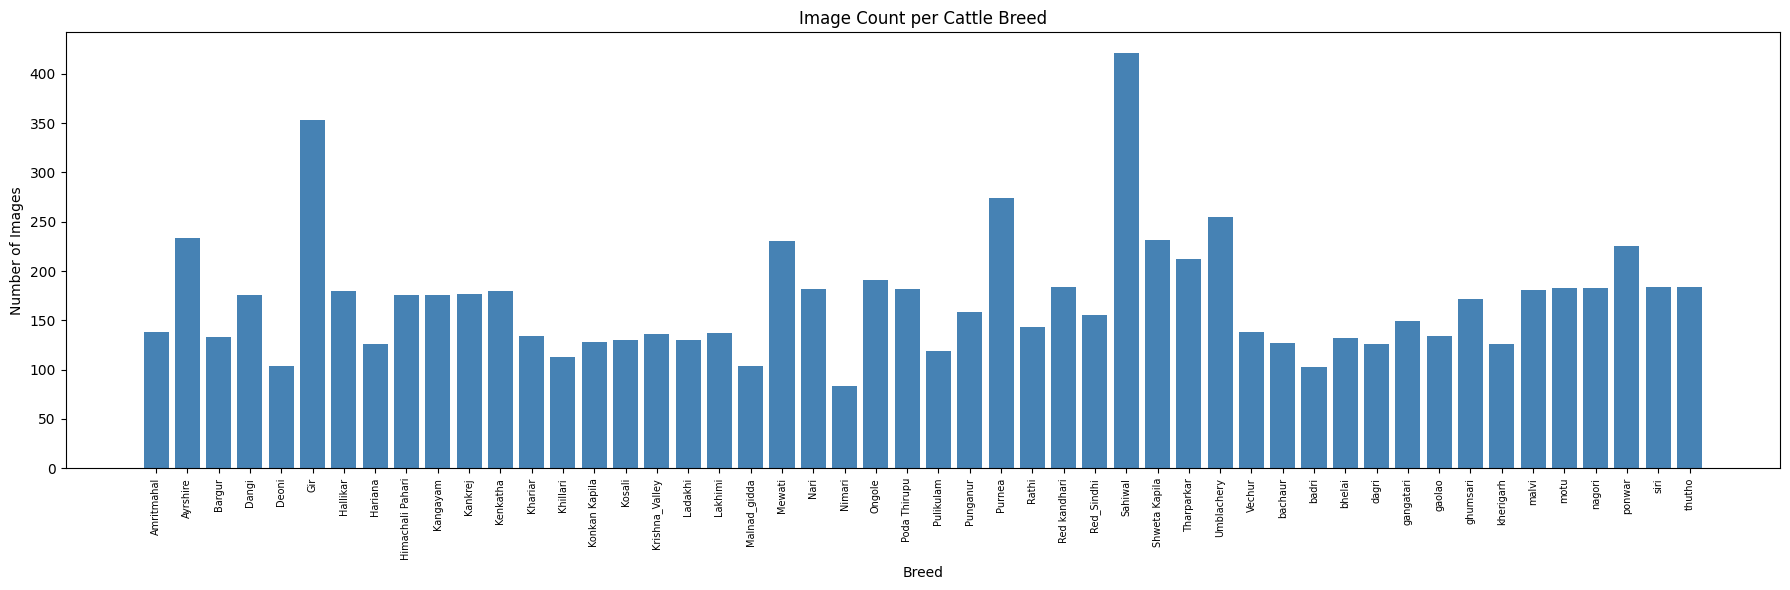

Total images: 8531


In [3]:
# Count images per breed
breed_counts = {}
for breed in breeds:
    breed_path = os.path.join(dataset_path, breed)
    if os.path.isdir(breed_path):
        count = len([
            f for f in os.listdir(breed_path)
            if f.lower().endswith(('.jpg', '.jpeg', '.png'))
        ])
        breed_counts[breed] = count

# Plot image count per breed
plt.figure(figsize=(18, 6))
plt.bar(breed_counts.keys(), breed_counts.values(), color='steelblue')
plt.xticks(rotation=90, fontsize=7)
plt.xlabel('Breed')
plt.ylabel('Number of Images')
plt.title('Image Count per Cattle Breed')
plt.tight_layout()
plt.show()

print(f"Total images: {sum(breed_counts.values())}")

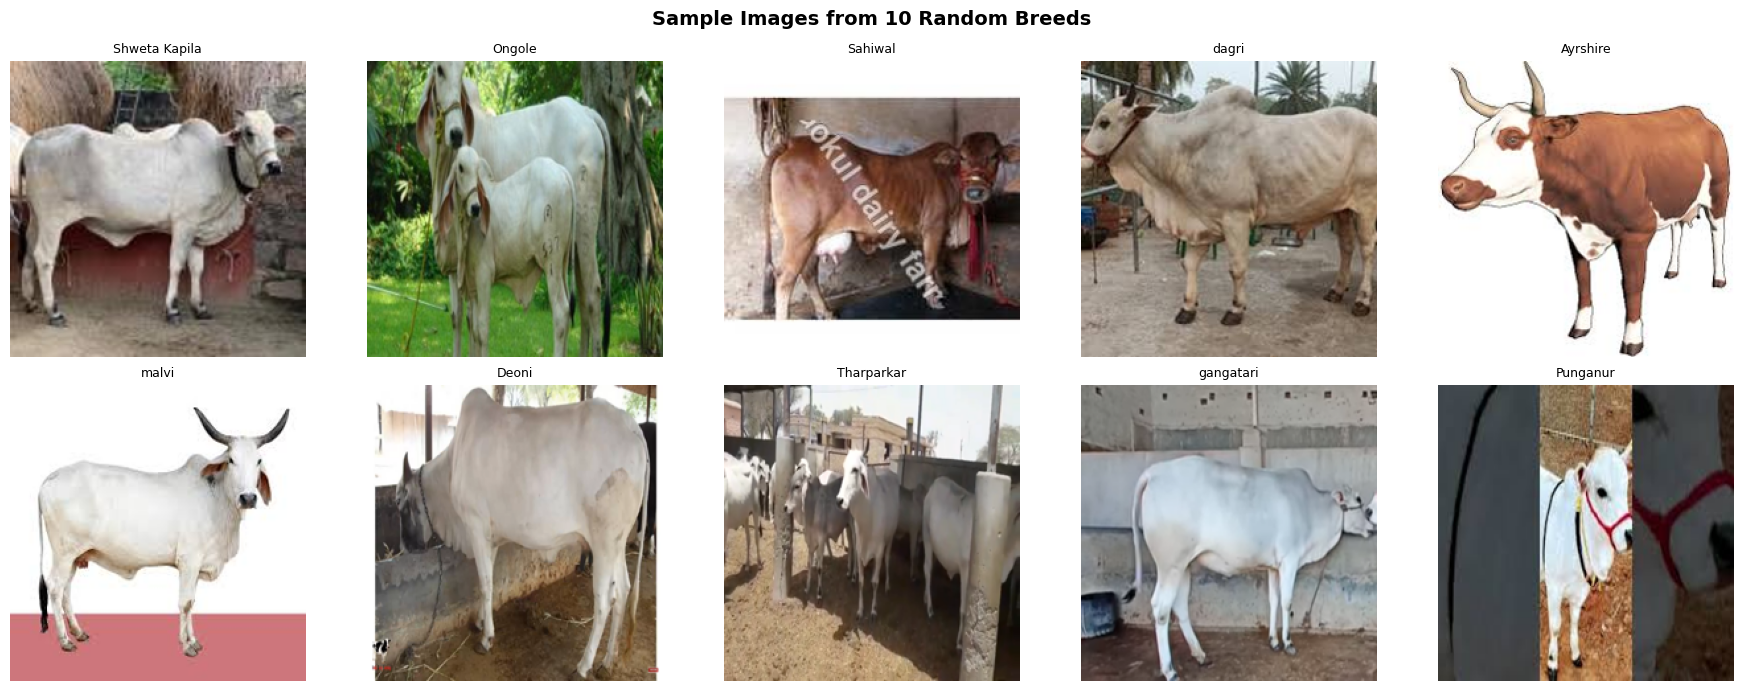

In [4]:
# Plot sample images from 10 random breeds
from PIL import Image

sample_breeds = random.sample(breeds, 10)
fig, axes = plt.subplots(2, 5, figsize=(18, 7))
axes = axes.flatten()

for i, breed in enumerate(sample_breeds):
    breed_path = os.path.join(dataset_path, breed)
    imgs = [f for f in os.listdir(breed_path) if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
    if imgs:
        img_path = os.path.join(breed_path, random.choice(imgs))
        img = Image.open(img_path).resize((224, 224))
        axes[i].imshow(img)
        axes[i].set_title(breed, fontsize=9)
        axes[i].axis('off')

plt.suptitle('Sample Images from 10 Random Breeds', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

## Step 3: Create 70 / 15 / 15 Train / Validation / Test Split

In [5]:
import math

split_base = "cattle_split"
for split in ['train', 'val', 'test']:
    os.makedirs(os.path.join(split_base, split), exist_ok=True)

random.seed(42)

for breed in breeds:
    breed_path = os.path.join(dataset_path, breed)
    if not os.path.isdir(breed_path):
        continue

    images = [
        f for f in os.listdir(breed_path)
        if f.lower().endswith(('.jpg', '.jpeg', '.png'))
    ]
    random.shuffle(images)

    n = len(images)
    n_train = math.floor(0.70 * n)
    n_val   = math.floor(0.15 * n)
    # rest goes to test

    splits = {
        'train': images[:n_train],
        'val':   images[n_train:n_train + n_val],
        'test':  images[n_train + n_val:]
    }

    for split_name, split_images in splits.items():
        dest_dir = os.path.join(split_base, split_name, breed)
        os.makedirs(dest_dir, exist_ok=True)
        for img_name in split_images:
            shutil.copy(
                os.path.join(breed_path, img_name),
                os.path.join(dest_dir, img_name)
            )

print("✅ Dataset split into train / val / test folders")

✅ Dataset split into train / val / test folders


## Step 4: Load Datasets with Augmentation

In [6]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
NUM_CLASSES = 50

train_ds = image_dataset_from_directory(
    os.path.join(split_base, 'train'),
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    seed=42
)

val_ds = image_dataset_from_directory(
    os.path.join(split_base, 'val'),
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    seed=42
)

test_ds = image_dataset_from_directory(
    os.path.join(split_base, 'test'),
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    seed=42,
    shuffle=False   # Keep order for confusion matrix
)

class_names = train_ds.class_names
print(f"Classes: {len(class_names)}")
print("✅ Datasets loaded")

Found 5949 files belonging to 50 classes.
Found 1254 files belonging to 50 classes.
Found 1328 files belonging to 50 classes.
Classes: 50
✅ Datasets loaded


In [7]:
# Normalization + Data Augmentation (only on train)
normalization_layer = layers.Rescaling(1./255)

data_augmentation = tf.keras.Sequential([
    layers.RandomFlip('horizontal'),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
    layers.RandomContrast(0.1),
])

def prepare_train(x, y):
    x = normalization_layer(x)
    x = data_augmentation(x, training=True)
    return x, y

def prepare(x, y):
    return normalization_layer(x), y

AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.map(prepare_train).cache().shuffle(1000).prefetch(AUTOTUNE)
val_ds   = val_ds.map(prepare).cache().prefetch(AUTOTUNE)
test_ds  = test_ds.map(prepare).cache().prefetch(AUTOTUNE)

print("✅ Normalization and augmentation applied")

✅ Normalization and augmentation applied


## Step 5: Model 1 — DenseNet121 (Transfer Learning)

In [8]:
def build_densenet():
    base = DenseNet121(weights='imagenet', include_top=False, input_shape=(224, 224, 3))
    base.trainable = False

    model = models.Sequential([
        base,
        layers.GlobalAveragePooling2D(),
        layers.BatchNormalization(),
        layers.Dense(256, activation='relu'),
        layers.Dropout(0.4),
        layers.Dense(NUM_CLASSES, activation='softmax')
    ])

    model.compile(
        optimizer='adam',
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

densenet_model = build_densenet()
densenet_model.summary()
print("✅ DenseNet121 model built")

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ densenet121 (Functional)        │ (None, 7, 7, 1024)     │     7,037,504 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1024)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1024)           │         4,096 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       262,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 50)             │        12,850 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,316,850 (27.91 MB)

 Trainable params: 277,298 (1.06 MB)

 Non-trainable params: 7,039,552 (26.85 MB)

✅ DenseNet121 model built


In [9]:
callbacks = [
    EarlyStopping(monitor='val_accuracy', patience=3, restore_best_weights=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, verbose=1)
]

history_densenet = densenet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=callbacks
)

print("✅ DenseNet121 training complete")

Epoch 1/10


2026-04-13 14:26:15.074992: W tensorflow/core/lib/png/png_io.cc:95] PNG warning: iCCP: known incorrect sRGB profile
2026-04-13 14:26:21.803981: W tensorflow/core/lib/png/png_io.cc:95] PNG warning: iCCP: known incorrect sRGB profile
2026-04-13 14:26:25.189037: I tensorflow/core/kernels/data/shuffle_dataset_op.cc:453] ShuffleDatasetV3:22: Filling up shuffle buffer (this may take a while): 53 of 1000
2026-04-13 14:26:45.124794: I tensorflow/core/kernels/data/shuffle_dataset_op.cc:453] ShuffleDatasetV3:22: Filling up shuffle buffer (this may take a while): 149 of 1000
2026-04-13 14:26:45.751520: W tensorflow/core/lib/png/png_io.cc:95] PNG warning: iCCP: profile 'ICC Profile': 0h: PCS illuminant is not D50
2026-04-13 14:26:46.434349: W tensorflow/core/lib/png/png_io.cc:95] PNG warning: iCCP: profile 'ICC Profile': 0h: PCS illuminant is not D50
2026-04-13 14:26:52.818301: I tensorflow/core/kernels/data/shuffle_dataset_op.cc:483] Shuffle buffer filled.


186/186 ━━━━━━━━━━━━━━━━━━━━ 246s 1s/step - accuracy: 0.1732 - loss: 3.3638 - val_accuracy: 0.4745 - val_loss: 1.9702 - learning_rate: 0.0010
Epoch 2/10
186/186 ━━━━━━━━━━━━━━━━━━━━ 194s 1s/step - accuracy: 0.4891 - loss: 1.7556 - val_accuracy: 0.5223 - val_loss: 1.6965 - learning_rate: 0.0010
Epoch 3/10
186/186 ━━━━━━━━━━━━━━━━━━━━ 192s 1s/step - accuracy: 0.5951 - loss: 1.3947 - val_accuracy: 0.5271 - val_loss: 1.6207 - learning_rate: 0.0010
Epoch 4/10
186/186 ━━━━━━━━━━━━━━━━━━━━ 184s 991ms/step - accuracy: 0.6728 - loss: 1.0941 - val_accuracy: 0.5415 - val_loss: 1.6261 - learning_rate: 0.0010
Epoch 5/10
186/186 ━━━━━━━━━━━━━━━━━━━━ 0s 816ms/step - accuracy: 0.7416 - loss: 0.8846
Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
186/186 ━━━━━━━━━━━━━━━━━━━━ 184s 987ms/step - accuracy: 0.7415 - loss: 0.8850 - val_accuracy: 0.5415 - val_loss: 1.6338 - learning_rate: 0.0010
Epoch 6/10
186/186 ━━━━━━━━━━━━━━━━━━━━ 186s 1s/step - accuracy: 0.7920 - loss: 0.7159 

## Step 6: Model 2 — MobileNetV2 (Transfer Learning)

In [10]:
def build_mobilenet():
    base = MobileNetV2(weights='imagenet', include_top=False, input_shape=(224, 224, 3))
    base.trainable = False

    model = models.Sequential([
        base,
        layers.GlobalAveragePooling2D(),
        layers.BatchNormalization(),
        layers.Dense(256, activation='relu'),
        layers.Dropout(0.4),
        layers.Dense(NUM_CLASSES, activation='softmax')
    ])

    model.compile(
        optimizer='adam',
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

mobilenet_model = build_mobilenet()
mobilenet_model.summary()
print("✅ MobileNetV2 model built")

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 1280)           │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 50)             │        12,850 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,603,890 (9.93 MB)

 Trainable params: 343,346 (1.31 MB)

 Non-trainable params: 2,260,544 (8.62 MB)

✅ MobileNetV2 model built


In [11]:
history_mobilenet = mobilenet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=callbacks
)

print("✅ MobileNetV2 training complete")

Epoch 1/10
186/186 ━━━━━━━━━━━━━━━━━━━━ 48s 248ms/step - accuracy: 0.1822 - loss: 3.5846 - val_accuracy: 0.4402 - val_loss: 2.0575 - learning_rate: 0.0010
Epoch 2/10
186/186 ━━━━━━━━━━━━━━━━━━━━ 44s 239ms/step - accuracy: 0.4936 - loss: 1.7852 - val_accuracy: 0.4577 - val_loss: 1.9098 - learning_rate: 0.0010
Epoch 3/10
186/186 ━━━━━━━━━━━━━━━━━━━━ 42s 228ms/step - accuracy: 0.6105 - loss: 1.2819 - val_accuracy: 0.4657 - val_loss: 1.9476 - learning_rate: 0.0010
Epoch 4/10
186/186 ━━━━━━━━━━━━━━━━━━━━ 0s 183ms/step - accuracy: 0.7055 - loss: 0.9999
Epoch 4: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
186/186 ━━━━━━━━━━━━━━━━━━━━ 41s 222ms/step - accuracy: 0.7054 - loss: 1.0002 - val_accuracy: 0.4769 - val_loss: 1.9583 - learning_rate: 0.0010
Epoch 5/10
186/186 ━━━━━━━━━━━━━━━━━━━━ 41s 221ms/step - accuracy: 0.7983 - loss: 0.6932 - val_accuracy: 0.4825 - val_loss: 1.9062 - learning_rate: 5.0000e-04
Epoch 6/10
186/186 ━━━━━━━━━━━━━━━━━━━━ 40s 217ms/step - accuracy: 0

## Step 7: Model 3 — SVM Baseline (on DenseNet features)

In [12]:
# Extract features using frozen DenseNet base
feature_extractor = tf.keras.Model(
    inputs=densenet_model.layers[0].input,
    outputs=densenet_model.layers[0].output  # DenseNet base output
)

def extract_features(dataset):
    features, labels = [], []
    for images, lbls in dataset:
        feats = feature_extractor(images, training=False)
        # Global average pooling manually
        feats = tf.reduce_mean(feats, axis=[1, 2]).numpy()
        features.append(feats)
        labels.append(lbls.numpy())
    return np.vstack(features), np.concatenate(labels)

print("Extracting training features...")
X_train_feat, y_train_feat = extract_features(train_ds)

print("Extracting test features...")
X_test_feat, y_test_feat = extract_features(test_ds)

print(f"Feature shapes — Train: {X_train_feat.shape}, Test: {X_test_feat.shape}")
print("✅ Features extracted")

Extracting training features...


2026-04-13 15:11:03.293256: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


Extracting test features...


2026-04-13 15:11:04.636517: W tensorflow/core/lib/png/png_io.cc:95] PNG warning: iCCP: known incorrect sRGB profile


Feature shapes — Train: (5949, 1024), Test: (1328, 1024)
✅ Features extracted


2026-04-13 15:12:17.755601: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


In [13]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_feat)
X_test_scaled  = scaler.transform(X_test_feat)

print("Training SVM classifier...")
svm_model = SVC(kernel='rbf', C=10, gamma='scale', max_iter=1000)
svm_model.fit(X_train_scaled, y_train_feat)

svm_preds = svm_model.predict(X_test_scaled)
svm_acc = accuracy_score(y_test_feat, svm_preds)
print(f"✅ SVM Test Accuracy: {svm_acc:.4f}")

Training SVM classifier...


/Users/krishna/Library/Python/3.9/lib/python/site-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=1000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(


✅ SVM Test Accuracy: 0.5610


## Step 8: Evaluate All Models on the Test Set

In [14]:
# Evaluate DenseNet on test set
densenet_loss, densenet_acc = densenet_model.evaluate(test_ds, verbose=0)
print(f"DenseNet121 Test Accuracy : {densenet_acc:.4f}")

# Evaluate MobileNetV2 on test set
mobilenet_loss, mobilenet_acc = mobilenet_model.evaluate(test_ds, verbose=0)
print(f"MobileNetV2  Test Accuracy : {mobilenet_acc:.4f}")

print(f"SVM          Test Accuracy : {svm_acc:.4f}")

DenseNet121 Test Accuracy : 0.5580
MobileNetV2  Test Accuracy : 0.4676
SVM          Test Accuracy : 0.5610


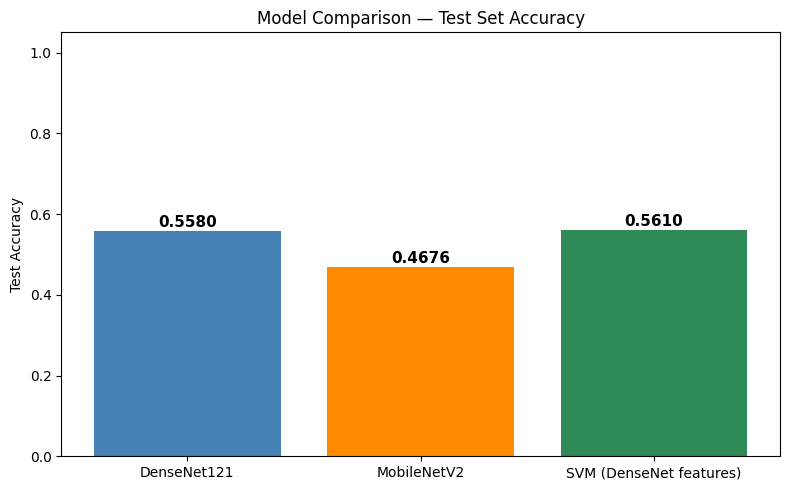

In [15]:
# Bar chart comparison
model_names = ['DenseNet121', 'MobileNetV2', 'SVM (DenseNet features)']
accuracies  = [densenet_acc, mobilenet_acc, svm_acc]

plt.figure(figsize=(8, 5))
bars = plt.bar(model_names, accuracies, color=['steelblue', 'darkorange', 'seagreen'])
plt.ylim(0, 1.05)
plt.ylabel('Test Accuracy')
plt.title('Model Comparison — Test Set Accuracy')
for bar, acc in zip(bars, accuracies):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
             f'{acc:.4f}', ha='center', fontsize=11, fontweight='bold')
plt.tight_layout()
plt.show()

## Step 9: Training Curves

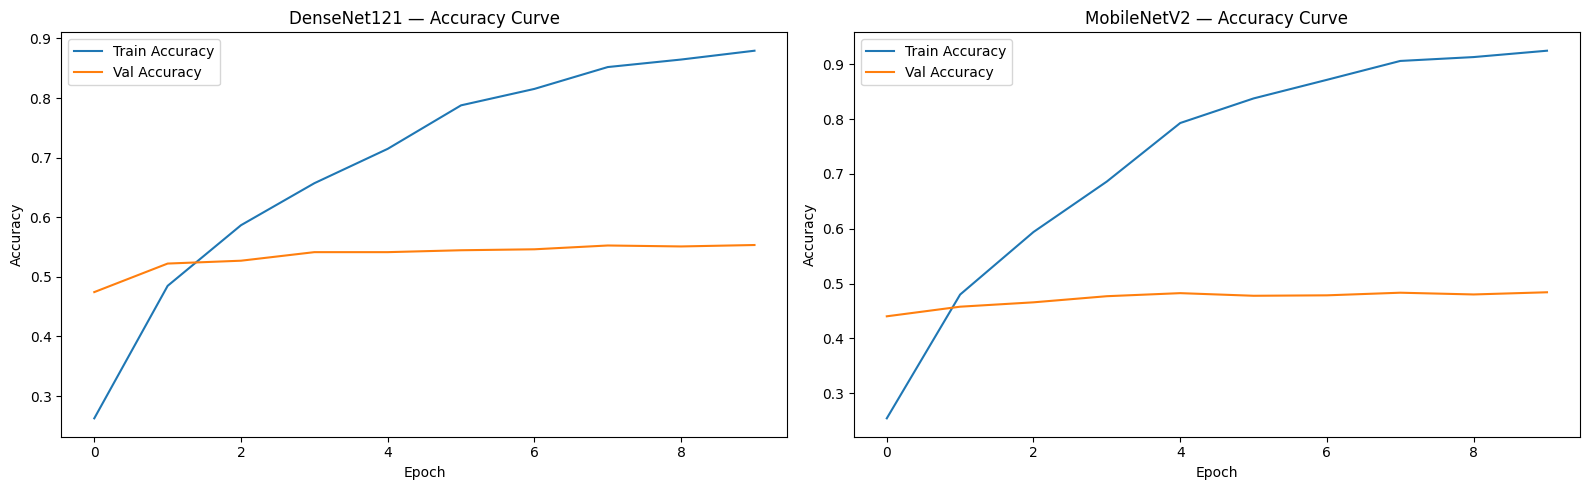

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

for ax, history, name in zip(
    axes,
    [history_densenet, history_mobilenet],
    ['DenseNet121', 'MobileNetV2']
):
    ax.plot(history.history['accuracy'],     label='Train Accuracy')
    ax.plot(history.history['val_accuracy'], label='Val Accuracy')
    ax.set_title(f'{name} — Accuracy Curve')
    ax.set_xlabel('Epoch')
    ax.set_ylabel('Accuracy')
    ax.legend()

plt.tight_layout()
plt.show()

## Step 10: Confusion Matrices

In [17]:
def get_predictions(model, dataset):
    y_true, y_pred = [], []
    for images, labels in dataset:
        preds = model.predict(images, verbose=0)
        y_true.extend(labels.numpy())
        y_pred.extend(np.argmax(preds, axis=1))
    return np.array(y_true), np.array(y_pred)

print("Getting DenseNet predictions...")
yt_dense, yp_dense = get_predictions(densenet_model, test_ds)

print("Getting MobileNet predictions...")
yt_mobile, yp_mobile = get_predictions(mobilenet_model, test_ds)

Getting DenseNet predictions...
Getting MobileNet predictions...


2026-04-13 15:14:00.770252: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


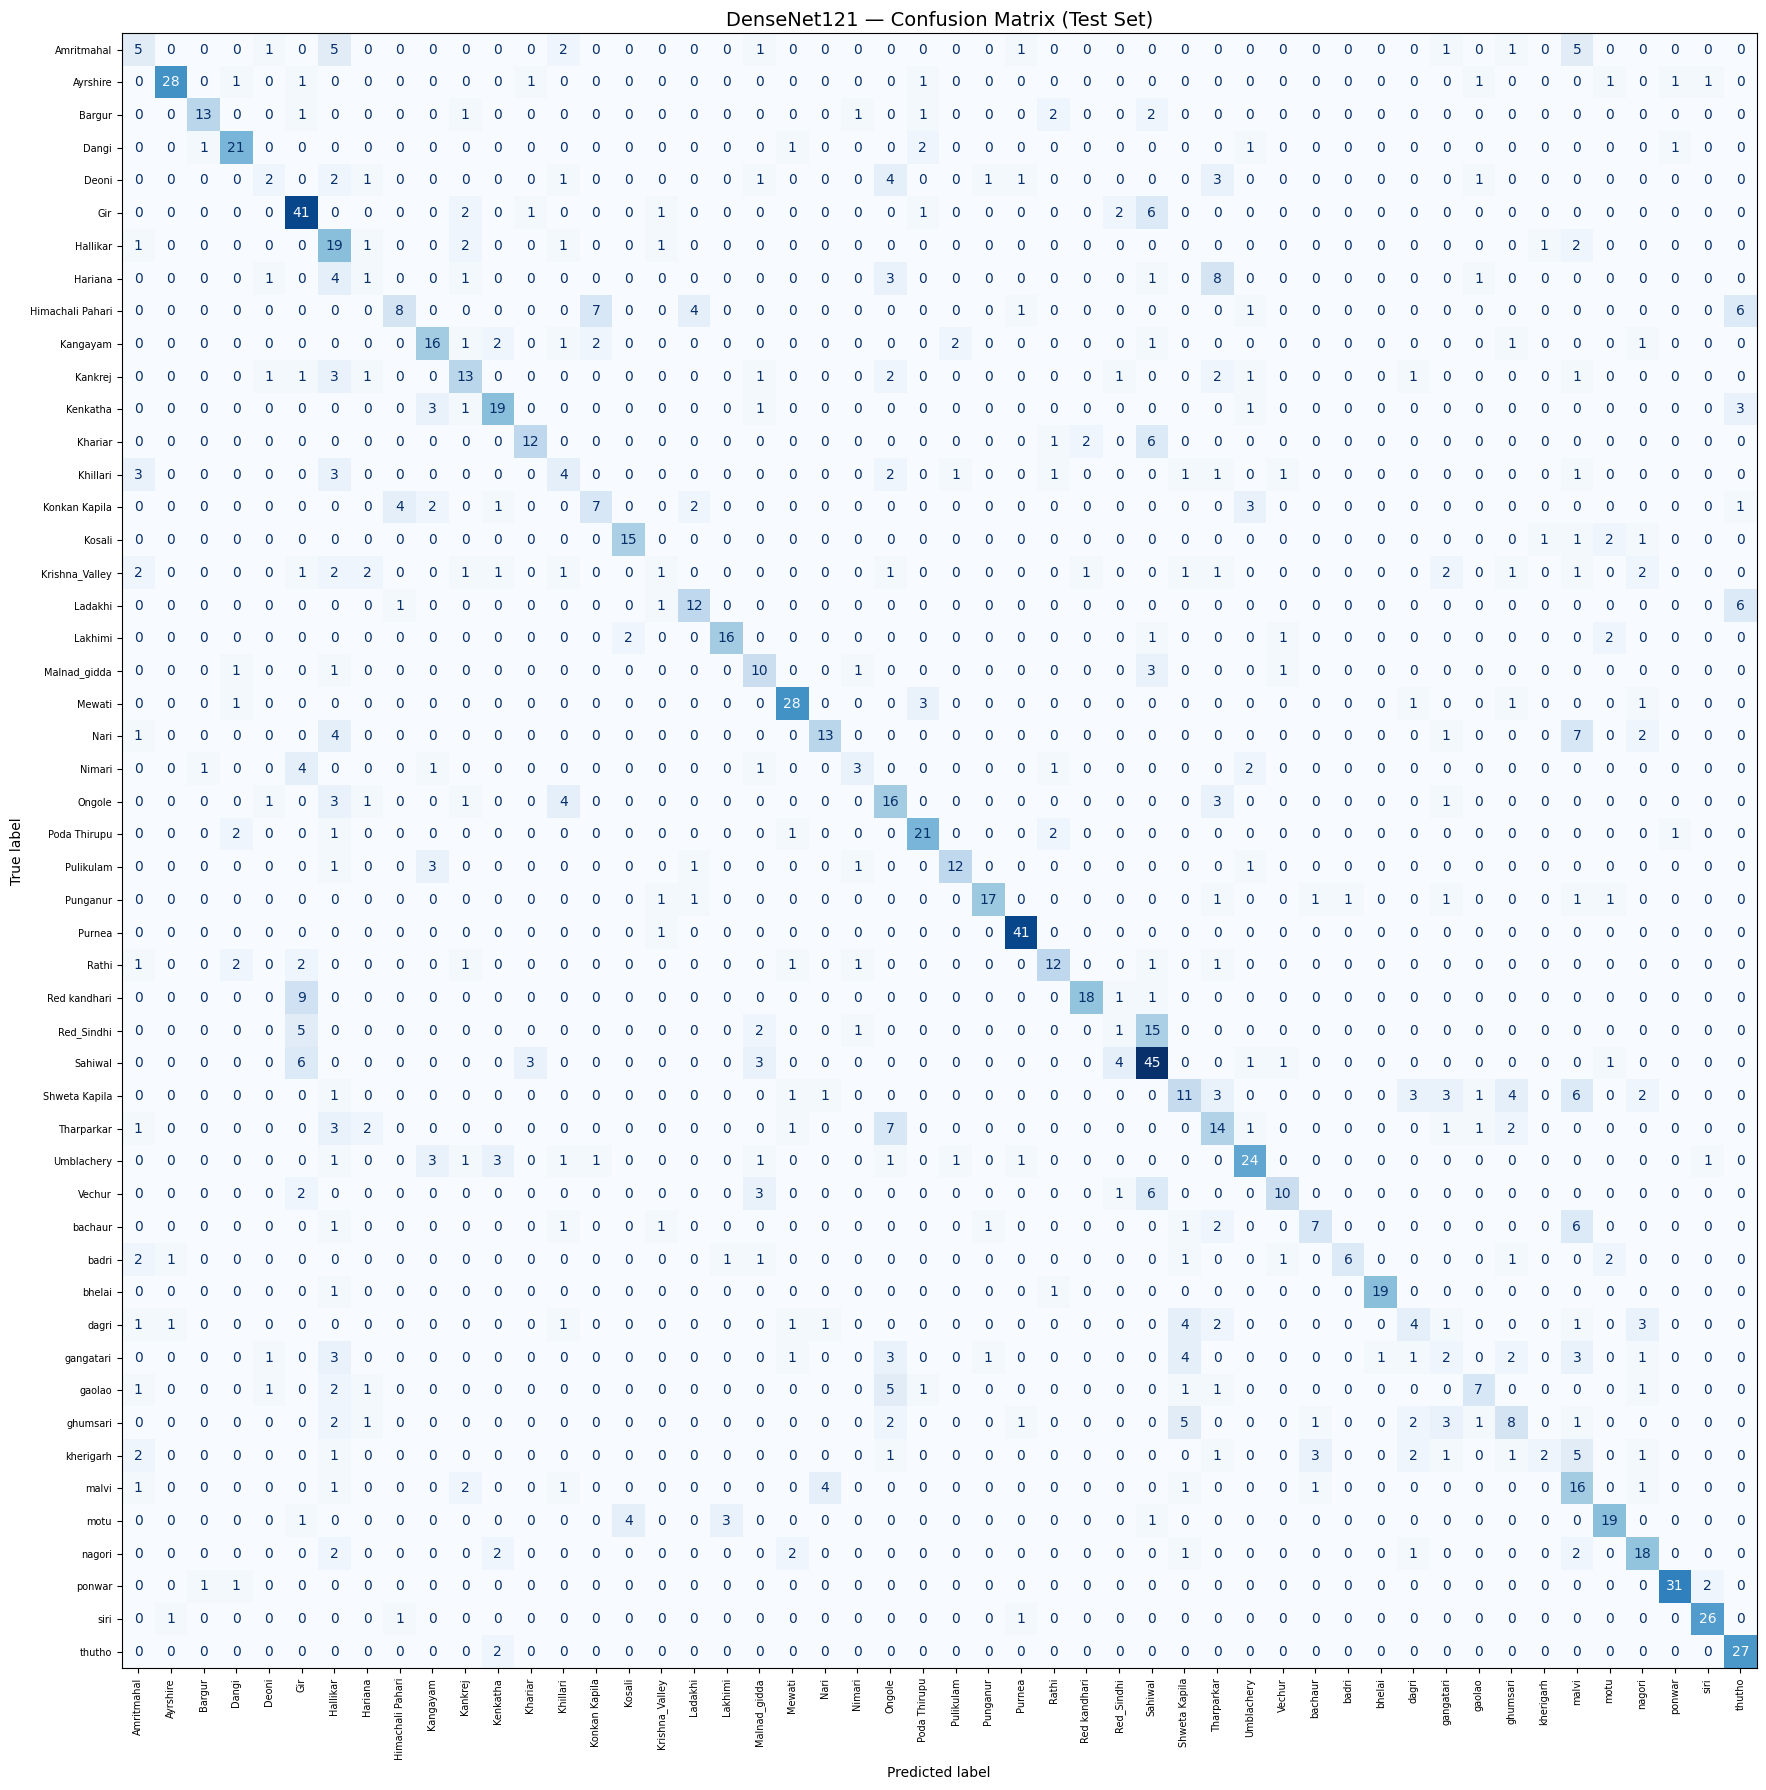

In [18]:
# DenseNet Confusion Matrix
cm_dense = confusion_matrix(yt_dense, yp_dense)

plt.figure(figsize=(20, 18))
disp = ConfusionMatrixDisplay(confusion_matrix=cm_dense, display_labels=class_names)
disp.plot(cmap='Blues', values_format='d', ax=plt.gca(), colorbar=False)
plt.xticks(rotation=90, fontsize=7)
plt.yticks(fontsize=7)
plt.title('DenseNet121 — Confusion Matrix (Test Set)', fontsize=14)
plt.tight_layout()
plt.show()

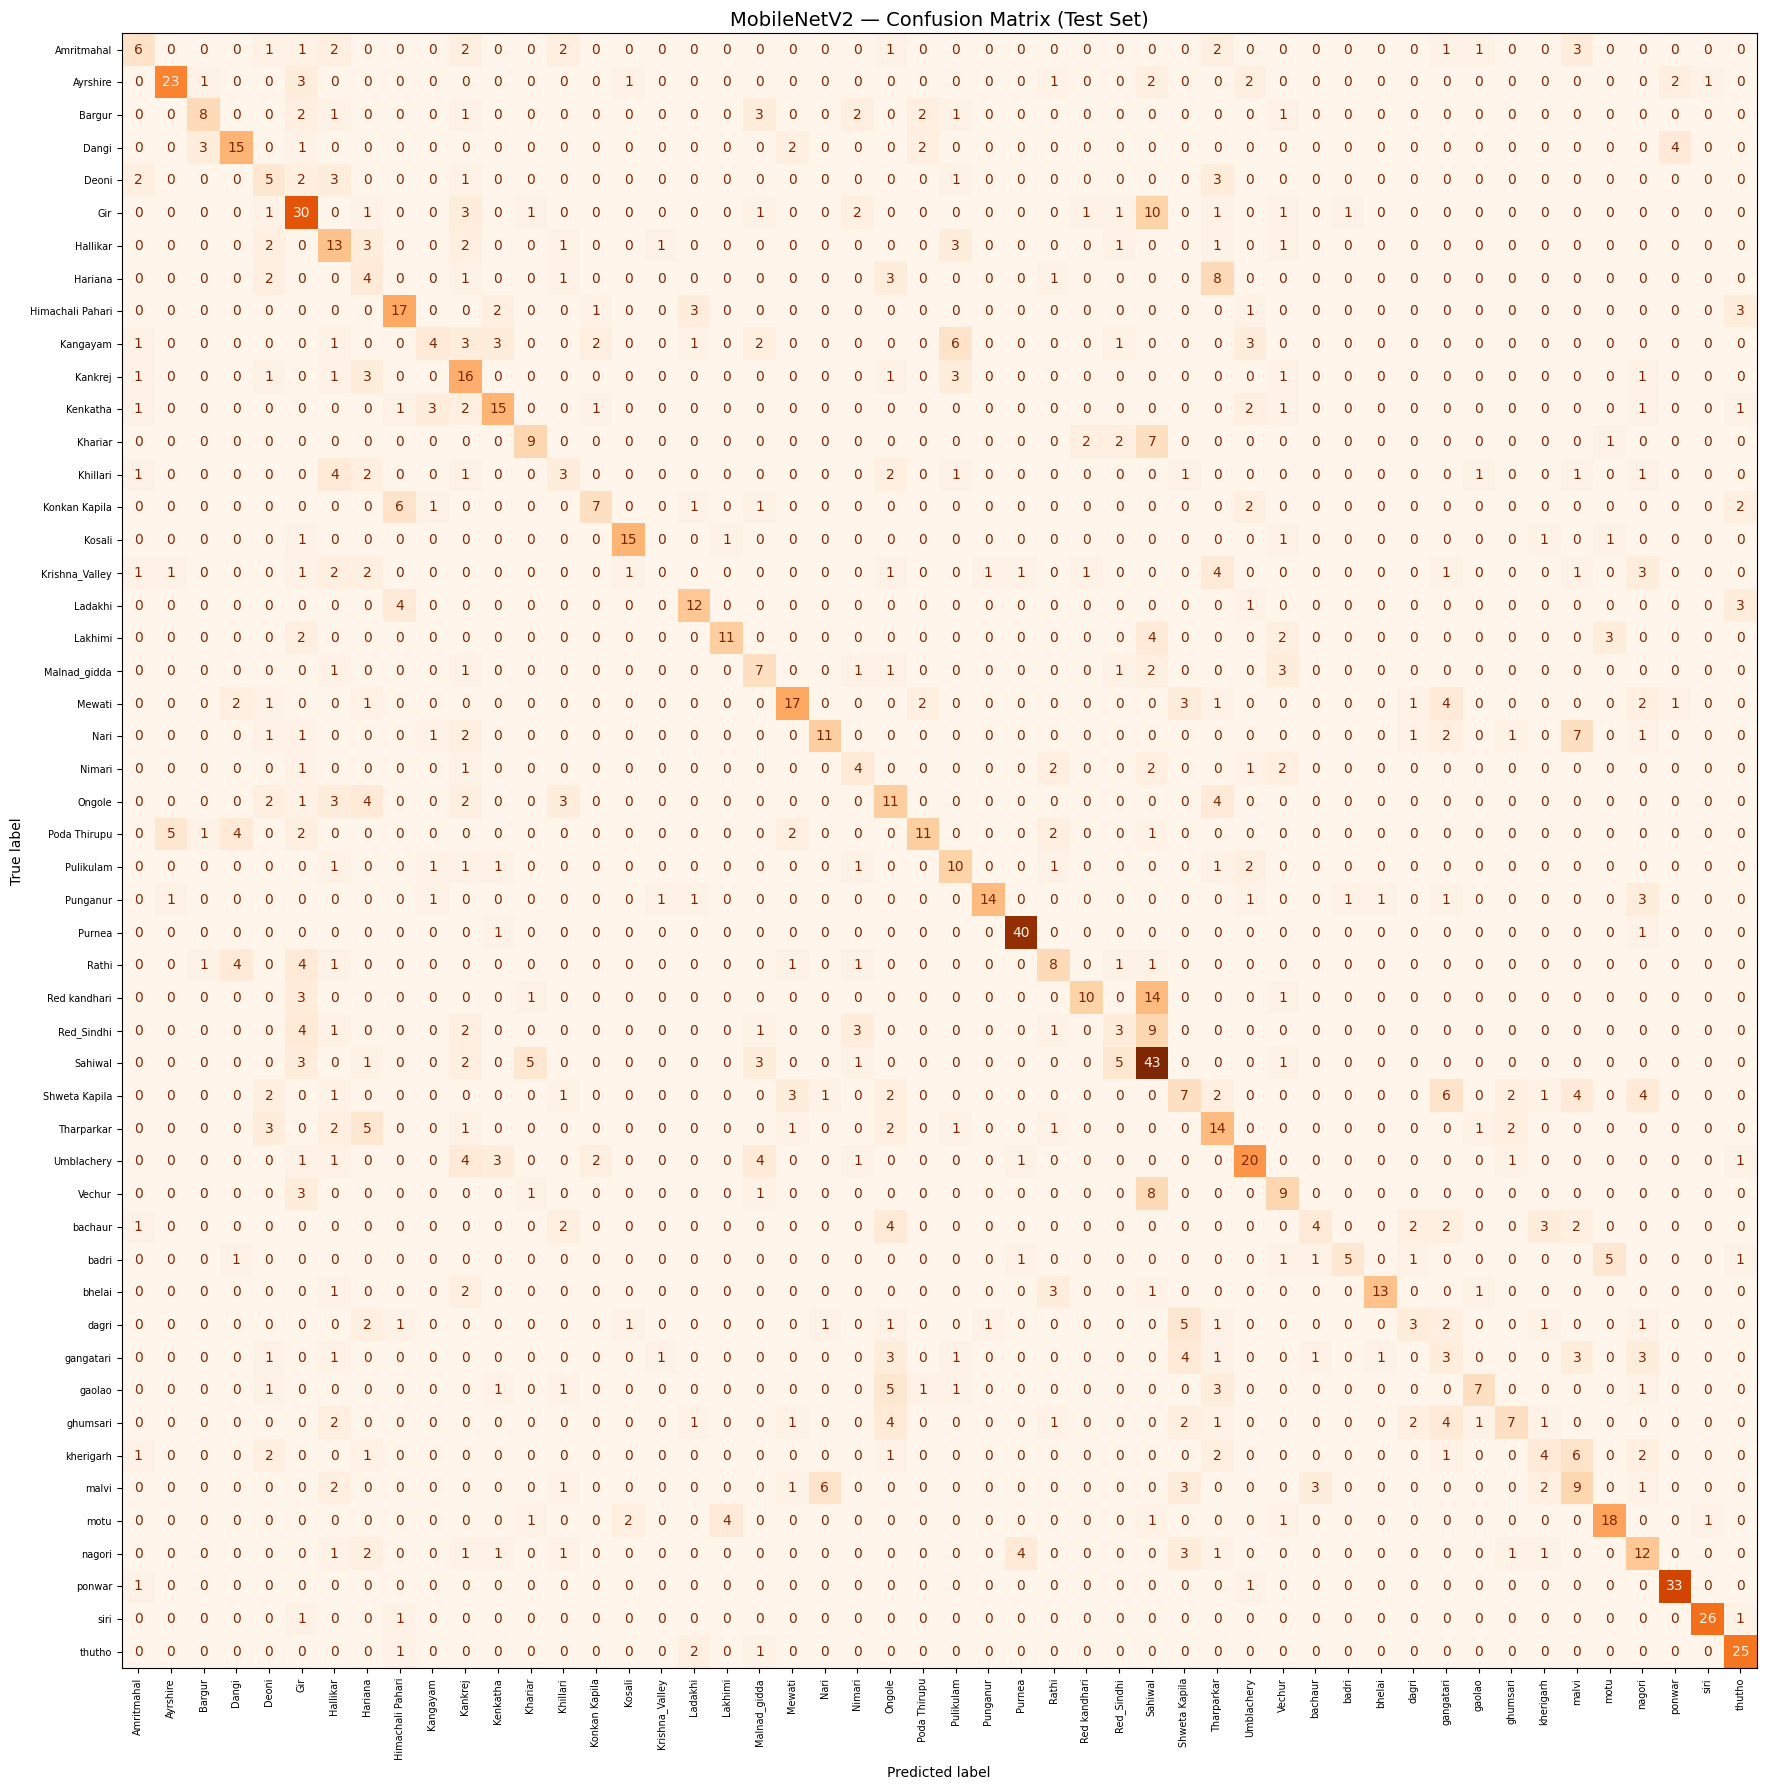

In [19]:
# MobileNetV2 Confusion Matrix
cm_mobile = confusion_matrix(yt_mobile, yp_mobile)

plt.figure(figsize=(20, 18))
disp2 = ConfusionMatrixDisplay(confusion_matrix=cm_mobile, display_labels=class_names)
disp2.plot(cmap='Oranges', values_format='d', ax=plt.gca(), colorbar=False)
plt.xticks(rotation=90, fontsize=7)
plt.yticks(fontsize=7)
plt.title('MobileNetV2 — Confusion Matrix (Test Set)', fontsize=14)
plt.tight_layout()
plt.show()

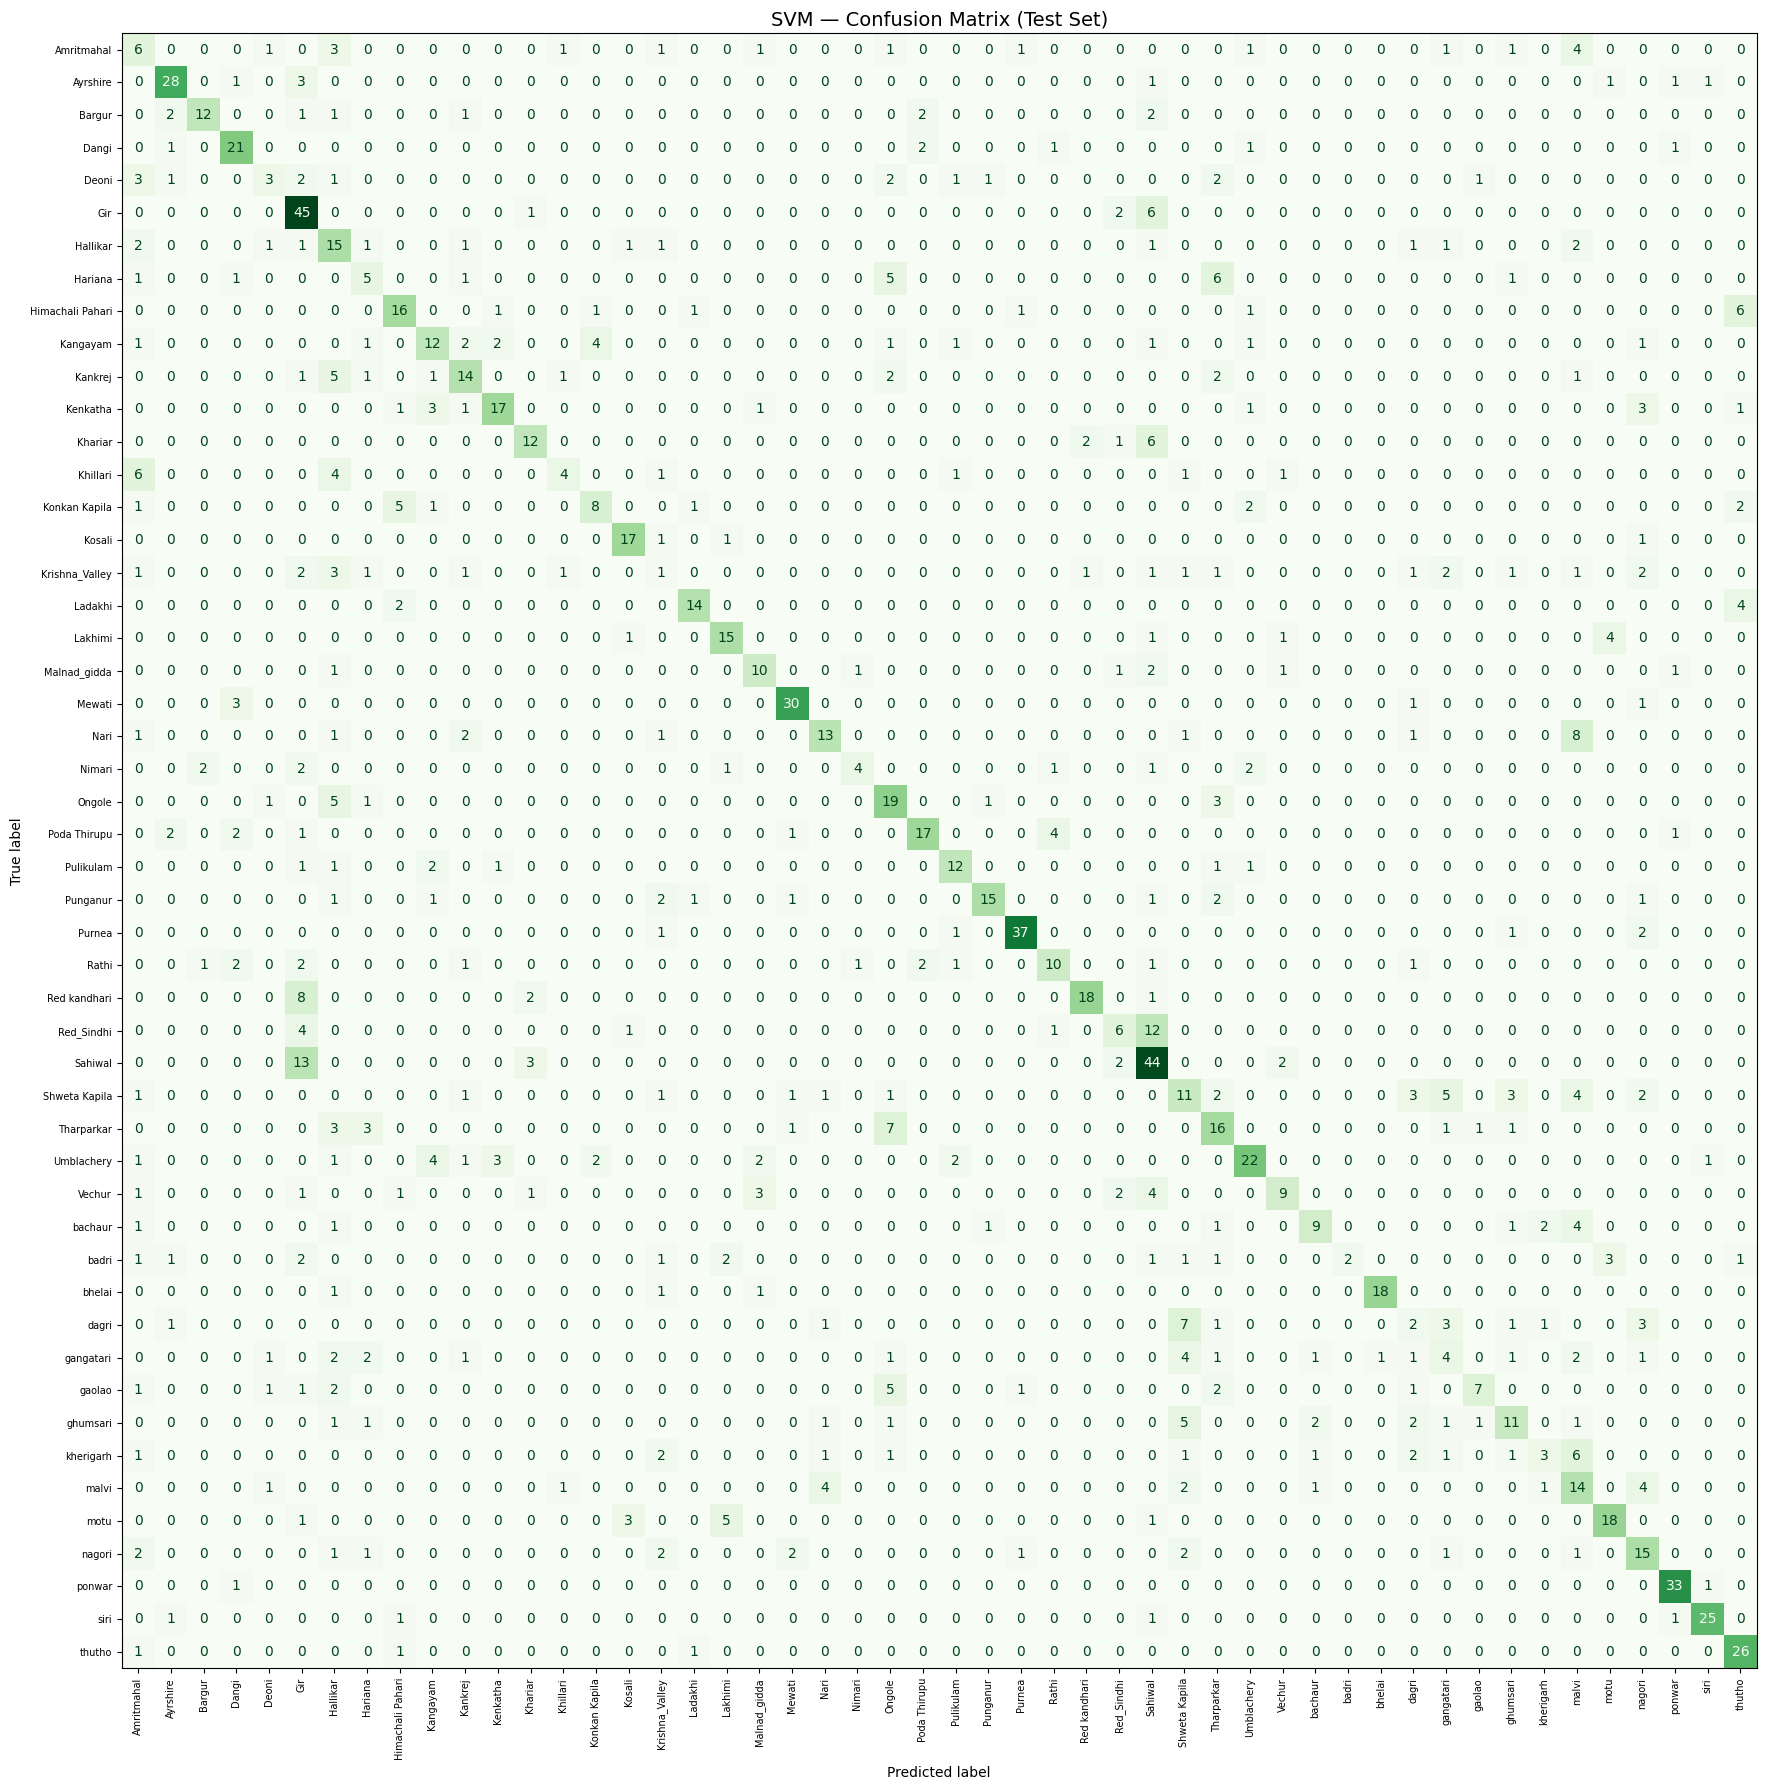

In [20]:
# SVM Confusion Matrix
cm_svm = confusion_matrix(y_test_feat, svm_preds)

plt.figure(figsize=(20, 18))
disp3 = ConfusionMatrixDisplay(confusion_matrix=cm_svm, display_labels=class_names)
disp3.plot(cmap='Greens', values_format='d', ax=plt.gca(), colorbar=False)
plt.xticks(rotation=90, fontsize=7)
plt.yticks(fontsize=7)
plt.title('SVM — Confusion Matrix (Test Set)', fontsize=14)
plt.tight_layout()
plt.show()

## Step 11: Classification Report

In [21]:
print("=" * 60)
print("DenseNet121 Classification Report")
print("=" * 60)
print(classification_report(yt_dense, yp_dense, target_names=class_names))

print("=" * 60)
print("MobileNetV2 Classification Report")
print("=" * 60)
print(classification_report(yt_mobile, yp_mobile, target_names=class_names))

DenseNet121 Classification Report
                  precision    recall  f1-score   support

      Amritmahal       0.24      0.23      0.23        22
        Ayrshire       0.90      0.78      0.84        36
          Bargur       0.81      0.62      0.70        21
           Dangi       0.72      0.78      0.75        27
           Deoni       0.25      0.12      0.16        17
             Gir       0.55      0.76      0.64        54
        Hallikar       0.29      0.68      0.40        28
         Hariana       0.09      0.05      0.06        20
Himachali Pahari       0.57      0.30      0.39        27
        Kangayam       0.57      0.59      0.58        27
         Kankrej       0.48      0.46      0.47        28
        Kenkatha       0.63      0.68      0.66        28
         Khariar       0.71      0.57      0.63        21
        Khillari       0.22      0.22      0.22        18
   Konkan Kapila       0.41      0.35      0.38        20
          Kosali       0.71      0.75

## Step 12: Save Models

In [22]:
densenet_model.save("densenet_cattle_model.h5")
mobilenet_model.save("mobilenet_cattle_model.h5")

import joblib
joblib.dump(svm_model, "svm_cattle_model.pkl")
joblib.dump(scaler,    "svm_scaler.pkl")

print("✅ All models saved successfully")

✅ All models saved successfully


## Summary

| Model | Test Accuracy |
|---|---|
| DenseNet121 | *see above* |
| MobileNetV2 | *see above* |
| SVM (DenseNet features) | *see above* |

**Key improvements over initial code:**
- Proper 70/15/15 train/val/test split with a truly held-out test set
- Data exploration: image counts and sample plots
- Data augmentation to reduce overfitting
- 3 models compared: DenseNet121, MobileNetV2, SVM
- EarlyStopping + ReduceLROnPlateau callbacks
- All evaluations done on the unseen test set
- Confusion matrices and classification reports for each model
- All duplicate import cells removed